# Select metamodel goals in the AoI buffer ring

Workflow:

1. Load **AoI**, **land**, and all hindcast coordinates catalogs from `hindcasts-reduced`.
2. Build the **inland buffer ring**: `ring = (AoI - AoI.buffer(-d)) - land`.
3. Place **random spaced targets** inside the ring (open water), then number them **clockwise along the AoI boundary** (starting at the westernmost point).
4. For each target, snap to the **nearest node in every hindcast** catalog.
5. (Optional) Filter out goals that are too far from any hindcast node.
6. Compute **adaptive open-sea propagation sectors** from the nearest **AoI boundary** point.
7. (Optional) Manually override goal directions, re-plot, and then save JSON + GeoPackage.

**Direction convention** (`utils/directions.py`): all stored `angles` are **nautical**
wave-from directions, **clockwise from North** (`0°` = N, `90°` = E). Each goal has
`[left, right]` with `left < right` (clockwise sector boundaries). If the sector crosses
North, `left` is negative (e.g. `[-10, 50]` = 350°->50° clockwise). This matches WHACS
and SnapWave forcing; LHS samples `dir` in that range and normalizes with `% 360`.

In [1]:
import json

import geopandas as gpd
import pandas as pd
from utils.config import CASE_DIR, PATHS, resolve
from utils.geometry import sectors as hc
from utils.viz import case_plots as plot

## Parameters

In [2]:
buffer_distance_m = 5_000.0
min_spacing_m = 40_000.0

# Optional cap: drop goals if any hindcast snap distance exceeds this threshold.
# Set to None to disable filtering.
max_hindcast_distance_m = 60_000.0

sector_margin_deg = 5.0
random_seed = 42

geo_crs = "EPSG:4326"
work_crs = "EPSG:32702"  # UTM 2S - Samoa

hindcasts_dir = CASE_DIR.parent / "QGIS/HyWorld/hindcasts-reduced"
land_path = hindcasts_dir / "land.gpkg"
goals_out_path = resolve("inputs/Goals/Samoa_Goals.json")
goals_gpkg_path = resolve("inputs/Goals/Samoa_Goals.gpkg")

print(f"AoI       : {resolve(PATHS['aoi_file'])}")
print(f"hindcasts : {hindcasts_dir}")
print(f"land      : {land_path}")
print(f"json      : {goals_out_path}")
print(f"gpkg      : {goals_gpkg_path}")
print(f"min dist  : {min_spacing_m} m")
print(f"max dist  : {max_hindcast_distance_m} m")

AoI       : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/AoI_Polygons/Samoa_AoI.shp
hindcasts : /home/tausiaj/GitHub-GeoOcean/HyGloW/QGIS/HyWorld/hindcasts-reduced
land      : /home/tausiaj/GitHub-GeoOcean/HyGloW/QGIS/HyWorld/hindcasts-reduced/land.gpkg
json      : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/Goals/Samoa_Goals.json
gpkg      : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/Goals/Samoa_Goals.gpkg
min dist  : 40000.0 m
max dist  : 60000.0 m


## Load inputs

In [3]:
aoi = gpd.read_file(resolve(PATHS["aoi_file"])).to_crs(geo_crs)
land = hc.load_land(land_path)
catalogs = hc.load_catalogs(hindcasts_dir)

print(f"AoI catalogs: {list(catalogs)}")
for name, gdf in catalogs.items():
    print(f"  {name:6s}: {len(gdf):4d} points")

AoI catalogs: ['codec', 'era5', 'whacs']
  codec :   25 points
  era5  :   45 points
  whacs :  641 points


## Buffer ring and random targets

In [4]:
ring_poly, ring_gdf = hc.build_ring(aoi, land, buffer_distance_m, work_crs)
targets = hc.random_targets_in_ring(
    ring_poly,
    land,
    min_spacing_m=min_spacing_m,
    work_crs=work_crs,
    random_seed=random_seed,
)
targets = hc.sort_targets_along_aoi(
    targets,
    aoi,
    work_crs=work_crs,
    clockwise=True,  # False = CCW; None = shapefile vertex order
    start_at="west",  # goal 1 starts at the westernmost AoI point
)

print(
    f"ring area : {gpd.GeoDataFrame(geometry=[ring_poly], crs=geo_crs).to_crs(work_crs).geometry.area.iloc[0] / 1e6:,.1f} km²"
)
print(f"targets   : {len(targets)}  (min spacing = {min_spacing_m / 1000:g} km)")
targets

ring area : 4,276.7 km²
targets   : 16  (min spacing = 40 km)


,geometry,goal_id
0,POINT (-173.20987 -13.43468),1
1,POINT (-172.91645 -13.11364),2
2,POINT (-172.28888 -13.04542),3
3,POINT (-171.91497 -13.28229),4
4,POINT (-171.40712 -13.4658),5
5,POINT (-170.90188 -13.85437),6
6,POINT (-170.40769 -13.85193),7
7,POINT (-170.15757 -14.13132),8
8,POINT (-170.26737 -14.58185),9
9,POINT (-170.65579 -14.79573),10


## Build goals dict (target, angles, hindcast snaps)

`angles` = nautical clockwise `[left, right]` per goal (see notebook intro).

In [5]:
sectors = hc.AoIRingSectors.from_aoi(aoi, work_crs)
goals = hc.build_goals_dict(
    targets,
    catalogs,
    sectors,
    work_crs=work_crs,
    margin_deg=sector_margin_deg,
)

if max_hindcast_distance_m is not None:
    goals = {
        goal_id: goal
        for goal_id, goal in goals.items()
        if max(v["distance_m"] for v in goal["hindcast"].values())
        <= max_hindcast_distance_m
    }
    keep_ids = set(goals)
    targets = targets[targets["goal_id"].astype(str).isin(keep_ids)].copy()

boundary_snaps = hc.boundary_snaps(targets, sectors, work_crs=work_crs)

summary_df = pd.DataFrame(
    [
        {
            "goal": k,
            "target_lon": v["target"]["longitude"],
            "target_lat": v["target"]["latitude"],
            "angles": v["angles"],
            "max_dist_m": max(h["distance_m"] for h in v["hindcast"].values()),
            **{f"{h}_fid": v["hindcast"][h]["fid"] for h in v["hindcast"]},
            **{f"{h}_dist_m": v["hindcast"][h]["distance_m"] for h in v["hindcast"]},
        }
        for k, v in goals.items()
    ]
)

print(f"goals kept: {len(goals)}")
summary_df

goals kept: 16


,goal,target_lon,target_lat,angles,max_dist_m,codec_fid,era5_fid,whacs_fid,codec_dist_m,era5_dist_m,whacs_dist_m
0,1,-173.209873,-13.434680,"[-203.9, 24.5]",48266.8,33048,149415,970692,48266.8,23851.8,3891.2
1,2,-172.916446,-13.113640,"[-138.0, 80.1]",15500.2,33048,148695,971045,14687.3,15500.2,6084.6
2,3,-172.288878,-13.045421,"[-93.3, 125.5]",49512.1,42051,148696,971050,49512.1,23443.5,7999.0
3,4,-171.914966,-13.282286,"[-49.6, 139.5]",57513.4,8711,149417,970816,57513.4,25780.5,8952.9
4,5,-171.407124,-13.465801,"[-78.8, 107.5]",53610.3,38621,149418,970702,53610.3,10740.0,6678.2
5,6,-170.901882,-13.854368,"[-107.2, 53.1]",19280.7,33076,150139,970365,17450.0,19280.7,6390.7
6,7,-170.407695,-13.851927,"[-74.7, 139.6]",50052.6,41928,150140,970368,50052.6,19173.8,6659.7
7,8,-170.157575,-14.131324,"[-28.5, 192.8]",45705.2,41928,150141,970143,45705.2,22371.1,7802.7
8,9,-170.267373,-14.581855,"[27.7, 238.2]",45179.9,41928,150860,969670,45179.9,26648.2,5400.4
9,10,-170.655787,-14.795726,"[49.7, 270.4]",43843.7,33077,151580,969427,43843.7,28129.5,8530.6


## Optional direction overrides (edit and re-run)

You can manually adjust directions before plotting/saving.
Use nautical clockwise `[left, right]` with `left < right`.

Example:

```python
direction_overrides = {
    "1": [-20, 60],
    "3": [95, 180],
}
```

/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/utils/viz/case_plots.py:217: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(loc="upper right", fontsize=8)


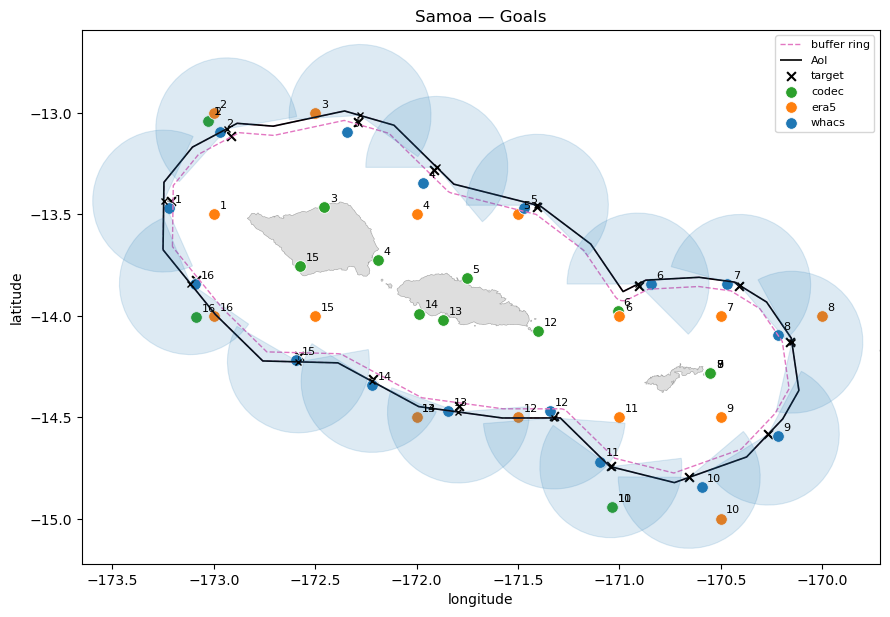

In [6]:
# Optionally edit this dictionary and rerun this cell.
direction_overrides: dict[str, list[float]] = {
    "4": [-90, 140],
    "5": [-90, 135],
    "6": [-90, 135],
    "15": [80, 300],
}

goals_final = json.loads(json.dumps(goals))
for goal_id, angles in direction_overrides.items():
    if goal_id not in goals_final:
        raise KeyError(f"Unknown goal_id in direction_overrides: {goal_id}")
    if len(angles) != 2 or angles[0] >= angles[1]:
        raise ValueError(
            f"{goal_id}: angles must be [left, right] with left < right, got {angles}"
        )
    goals_final[goal_id]["angles"] = [float(angles[0]), float(angles[1])]

fig, ax = plot.plot_base_map(
    title="Goals",
    show_topobathy=False,
    land=land,
    ring=ring_gdf,
)
plot.plot_sectors(targets, goals_final, boundary_snaps, ax)
targets.plot(ax=ax, color="black", markersize=40, marker="x", label="target")

plot.plot_points(
    hc.hindcast_snaps_gdf(goals_final),
    ax,
    color_col="catalog",
    label_col="goal_id",
    color_map=plot.HINDCAST_COLORS,
)

minx, miny, maxx, maxy = aoi.total_bounds
pad = 0.4
ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)
ax.set_aspect("equal", adjustable="box")

fig.tight_layout()

## Save goals JSON and QGIS GeoPackage

After saving, update `Samoa.json` with your selected goals JSON path:

```json
"simulations": {
    "goals_file": "inputs/goals/Samoa_goals.json"
}
```

In [7]:
goals_to_save = goals_final if "goals_final" in locals() else goals

goals_out_path.parent.mkdir(parents=True, exist_ok=True)

with goals_out_path.open("w", encoding="utf-8") as f:
    json.dump({"goals": goals_to_save}, f, indent=4)
    f.write("\n")

hc.save_goals_gpkg(
    goals_to_save, targets, boundary_snaps, goals_gpkg_path, ring=ring_gdf
)

print(f"Wrote {len(goals_to_save)} goal(s) to:")
print(f"  {goals_out_path}")
print(f"  {goals_gpkg_path}")
print(
    "\nGPKG layers: targets, boundary_snaps, sectors, links, buffer_ring, "
    "codec, era5, whacs"
)
print(json.dumps({"goals": goals_to_save}, indent=4))

Wrote 16 goal(s) to:
  /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/Goals/Samoa_Goals.json
  /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/Goals/Samoa_Goals.gpkg

GPKG layers: targets, boundary_snaps, sectors, links, buffer_ring, codec, era5, whacs
{
    "goals": {
        "1": {
            "target": {
                "longitude": -173.209873,
                "latitude": -13.43468
            },
            "angles": [
                -203.9,
                24.5
            ],
            "hindcast": {
                "codec": {
                    "fid": 33048,
                    "longitude": -173.02700000000002,
                    "latitude": -13.037,
                    "distance_m": 48266.8
                },
                "era5": {
                    "fid": 149415,
                    "longitude": -173.0,
                    "latitude": -13.5,
                    "distance_m": 23851.8
                },
                "whacs": {
                    "fid": 970692,
